In [32]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *
from multiply_connected_pipe.t_shaped import TShaped

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### geometry creation

In [34]:
# Goal 1: Create T-shaped and L-shaped pipe junctions

print("Creating 十-shaped pipe junctions...")


ls = np.array([
    [10,0],
    [0,10],
    [-10,0],
    [0,-10],
])

rs = np.array([1,1,1,1])

corner_size = 1
cross_shaped = NLets(ls,rs,corner_size)
t_shaped = TShaped(10,1,corner_size)


eps = 1e-8
cross_shaped.build_geometry(required_tol=eps)
t_shaped.build_geometry(required_tol=eps)

print(f"十-pipe: {t_shaped.n_pts} boundary points")
print(f"T-pipe: {t_shaped.n_pts} boundary points")

Creating 十-shaped pipe junctions...
1
1
1
1
1
1
十-pipe: 3180 boundary points
T-pipe: 3180 boundary points


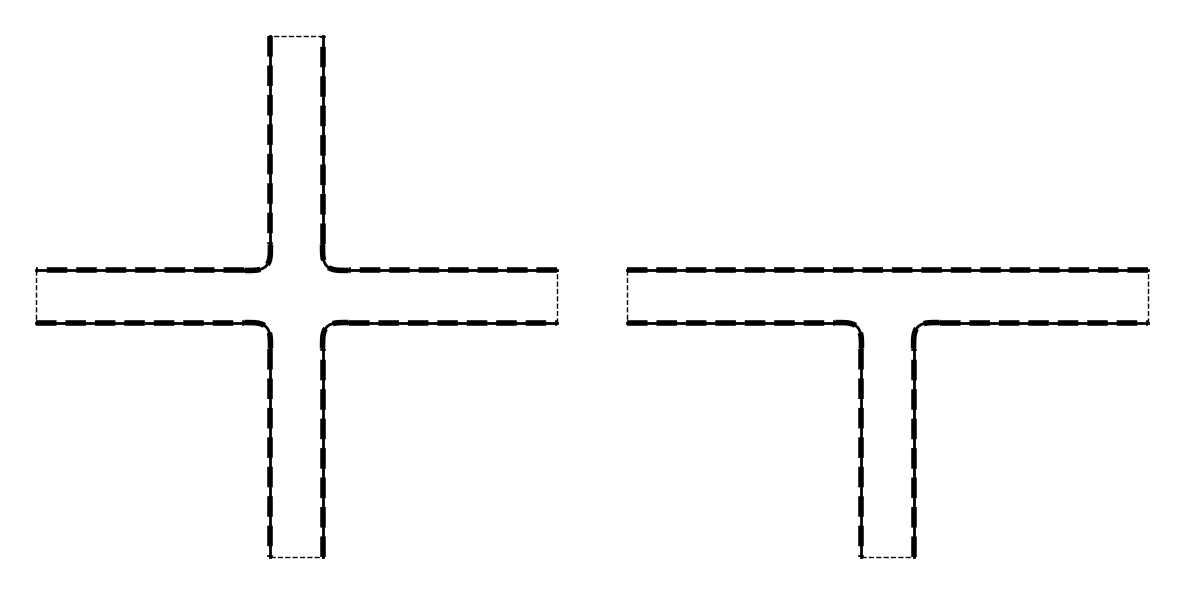

In [36]:
# Visualize the pipe geometries using the boundary plotting method
fig, axes = plt.subplots(1,2,tight_layout=True,sharey=True)

# Plot T-shaped pipe
axes[0].set_aspect('equal')
axes[0].axis('off')
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[0],color='k')

axes[1].set_aspect('equal')
axes[1].axis('off')
t_shaped.exterior_boundary.plot_plyg_bdr(axes[1],color='k')

plt.show()

In [37]:
# Goal 2: Solve for characteristic flows with Poiseuille boundary conditions
print("Building complete solver for T-shaped pipes...")
# Build complete solvers - this includes geometry, matrices, and flow solutions
eps = 1e-8
cross_shaped.build(required_tol=eps, fmm=True, density=20)
t_shaped.build(required_tol=eps, fmm=True, density=20)

Building complete solver for T-shaped pipes...





/Users/haiy/git/fmm2d/python/fmm2dpy/fmm2d.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  out.pottarg,out.gradtarg,out.ier = lfmm.cfmm2d_t_d_g(eps,sources,dipstr,targets)


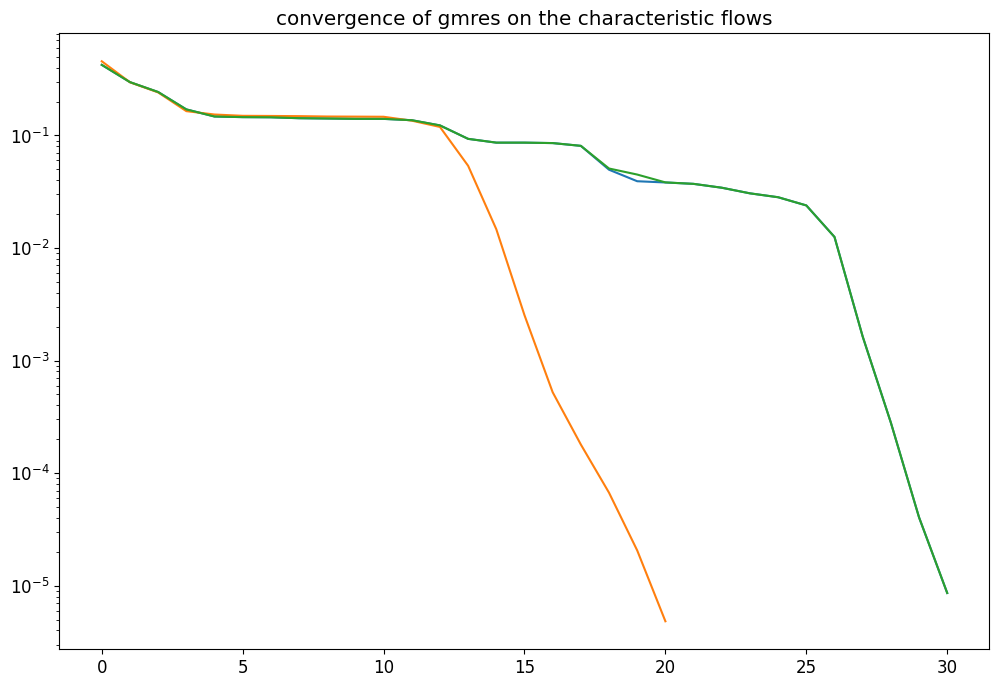

In [9]:
for c in cross_shaped.callbacks:
    plt.semilogy(c.residuals)
plt.title('convergence of gmres on the characteristic flows')
plt.show()

#### flows 

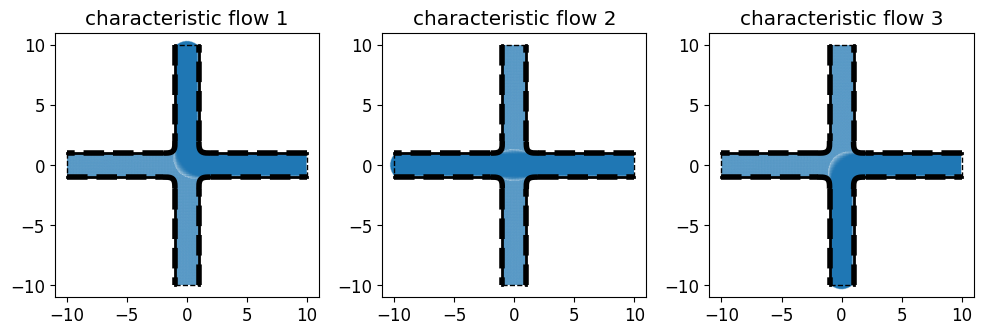

In [11]:
xs = cross_shaped.xs
ys = cross_shaped.ys

fig, axes = plt.subplots(1,3, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')


u0,v0,p0,o0 = cross_shaped.fields_with_fluxes(np.array([1,0,0]),0,0)
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].quiver(xs, ys, u0, v0, scale=40, color='C0', width=0.003)
axes[0].set_title('characteristic flow 1')



axes[1].set_aspect('equal')
u1,v1,p1,o1 = cross_shaped.fields_with_fluxes(np.array([0,1,0]),0,0)
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].quiver(xs, ys, u1, v1, scale=40, color='C0', width=0.003)
axes[1].set_title('characteristic flow 2')

axes[2].set_aspect('equal')
u2,v2,p2,o2 = cross_shaped.fields_with_fluxes(np.array([0,0,1]),0,0)
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[2], color='k')
axes[2].quiver(xs, ys, u2, v2, scale=40, color='C0', width=0.003)
axes[2].set_title('characteristic flow 3')

plt.show()

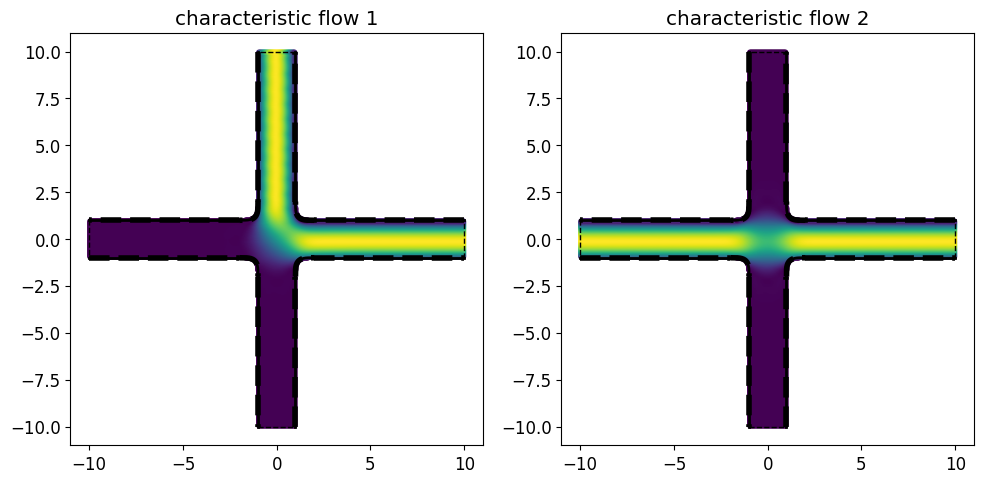

In [13]:
xs = cross_shaped.xs
ys = cross_shaped.ys

step = 1

fig, axes = plt.subplots(1,2, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = cross_shaped.fields_with_fluxes(np.array([1,0,0]),0,0)
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].scatter(xs, ys, c=np.linalg.norm(np.array([u0,v0]),axis=0),s=10)
axes[0].set_title('characteristic flow 1')




axes[1].set_aspect('equal')
u1,v1,p1,o1 = cross_shaped.fields_with_fluxes(np.array([0,1,0]),0,0)
cross_shaped.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].scatter(xs, ys, c=np.linalg.norm(np.array([u1,v1]),axis=0),s=10)

axes[1].set_title('characteristic flow 2')

plt.show()

#### assembling the pipes

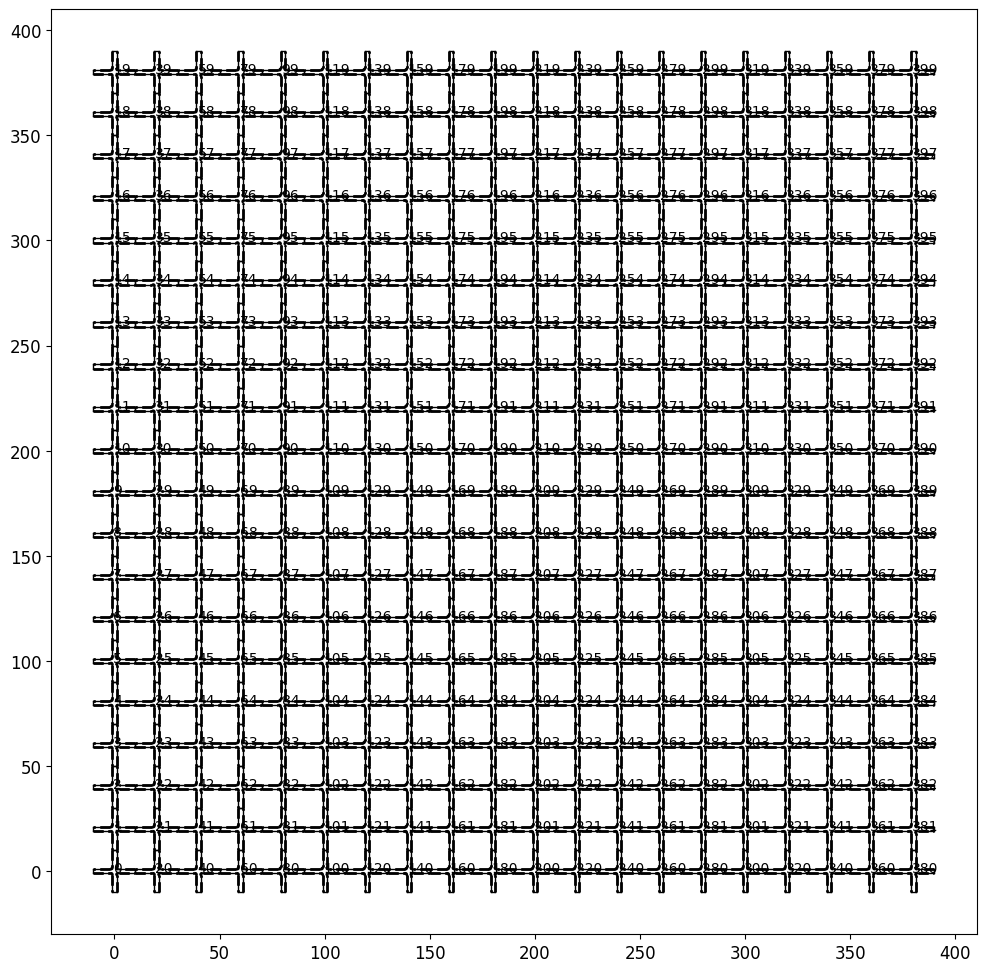

In [30]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

n_rep_x = 20
n_rep_y = 20


pipes = [RealPipe(cross_shaped,20*i,20*j,0) \
    for i in range(n_rep_x) \
    for j in range(n_rep_y)] 


for i,pipe in enumerate(pipes):
    pipe.plot_plyg_bdr(ax)
    x = np.mean(pipe.xs) - 0.5
    y = np.mean(pipe.ys) - 0.5
    ax.text(x,y,f'{i}',fontsize=10)

ax.set_aspect('equal')
# ax.axis('off')

plt.show()

In [25]:
import pickle

with open('pipe.pkl', 'wb') as f:
    pickle.dump(cross_shaped, f)


In [26]:
import pickle

with open('pipe.pkl', 'rb') as f:
    cross_shaped = pickle.load(f)
